# 02 — LP-FT Baseline (Focal Loss + Alpha Balanced)

**Protocol LP-FT:**
- Phase 1: 8 epochs, head only (base.trainable=False), LR=1e-3
- Phase 2: 25 epochs, full unfreeze, LR=1e-5

**Loss:** Focal Loss cu alpha balanced (sklearn-style inverse frequency, normalized).
Diferit față de notebook 01 (sparse CCE + class_weight) — aici testăm dacă focal loss
îmbunătățește minoritățile (df, vasc).

**Output:** `experiments/resnet152v2/tier{1-5}/B_lpft/`


## 1. Setup


In [1]:
from google.colab import drive
drive.mount('/content/drive')
print('Drive mounted')

Mounted at /content/drive
Drive mounted


In [2]:
import os
import json
import time
import random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import backend as K
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    precision_recall_fscore_support,
)

# ─── REPRODUCIBILITY ───
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print(f'TF: {tf.__version__}')
print(f'GPU: {tf.config.list_physical_devices("GPU")}')
print(f'Seed: {SEED}')

TF: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Seed: 42


In [3]:
# ─── PATHS ───
DRIVE_BASE = Path('/content/drive/MyDrive/Thesis')
PIPELINE_DIR = DRIVE_BASE / 'pipeline_outputs'

TFRECORDS_DIR = PIPELINE_DIR / 'step4_tfrecords'   # val/, test/, tier5/
STEP2_DIR = PIPELINE_DIR / 'step2'                 # tier{N}_train.csv
EXPERIMENTS_DIR = DRIVE_BASE / 'experiments' / 'resnet152v2'
EXPERIMENTS_DIR.mkdir(parents=True, exist_ok=True)

# ─── HYPERPARAMETERS ───
IMG_SIZE = 224
NUM_CLASSES = 7
BATCH_SIZE = 32
DENSE1_UNITS = 1024
DENSE2_UNITS = 512
DROPOUT_RATE = 0.3
ROTATION_MAX_DEG = 20
ZOOM_RANGE = 0.1

PAPER_TRAINABLE_PARAMS = 60_817_543

# ─── LABELS ───
IDX_TO_LABEL = {0: 'akiec', 1: 'bcc', 2: 'bkl', 3: 'df', 4: 'mel', 5: 'nv', 6: 'vasc'}
CLASS_NAMES = [IDX_TO_LABEL[i] for i in range(NUM_CLASSES)]

print(f'TFRecords:   {TFRECORDS_DIR.exists()} {TFRECORDS_DIR}')
print(f'Step2:       {STEP2_DIR.exists()} {STEP2_DIR}')
print(f'Experiments: {EXPERIMENTS_DIR}')

for split in ['val', 'test', 'tier5']:
    d = TFRECORDS_DIR / split
    if d.exists():
        shards = sorted(d.glob('*.tfrecord'))
        print(f'  {split}: {len(shards)} shards')
    else:
        print(f'  [WARNING] {split}/ missing!')

TFRecords:   True /content/drive/MyDrive/Thesis/pipeline_outputs/step4_tfrecords
Step2:       True /content/drive/MyDrive/Thesis/pipeline_outputs/step2
Experiments: /content/drive/MyDrive/Thesis/experiments/resnet152v2
  val: 3 shards
  test: 3 shards
  tier5: 21 shards


## 2. Data pipeline


In [4]:
FEATURE_DESC = {
    'image_id':    tf.io.FixedLenFeature([], tf.string),
    'label':       tf.io.FixedLenFeature([], tf.int64),
    'lesion_id':   tf.io.FixedLenFeature([], tf.string),
    'source':      tf.io.FixedLenFeature([], tf.string),
    'image_bytes': tf.io.FixedLenFeature([], tf.string),
}


def parse_example(example_proto):
    return tf.io.parse_single_example(example_proto, FEATURE_DESC)


def decode_image(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['lesion_id']


def decode_with_source(parsed):
    img = tf.io.decode_jpeg(parsed['image_bytes'], channels=3)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    return img, parsed['label'], parsed['source']


def get_split_files(split_name):
    pattern = str(TFRECORDS_DIR / split_name / '*.tfrecord')
    files = sorted(tf.io.gfile.glob(pattern))
    if not files:
        raise FileNotFoundError(f'No TFRecords found for split: {split_name}')
    return files


TRAIN_FILES = get_split_files('tier5')
VAL_FILES = get_split_files('val')
TEST_FILES = get_split_files('test')

print(f'Train pool: {len(TRAIN_FILES)} shards')
print(f'Val:        {len(VAL_FILES)} shards')
print(f'Test:       {len(TEST_FILES)} shards')

Train pool: 21 shards
Val:        3 shards
Test:       3 shards


In [5]:
def get_tier_lesion_ids(tier):
    if tier == 5:
        return None
    csv_path = STEP2_DIR / f'tier{tier}_train.csv'
    df = pd.read_csv(csv_path)
    return set(df['lesion_id'].astype(str).tolist())


def make_lesion_filter(allowed_ids):
    keys = tf.constant(sorted(list(allowed_ids)), dtype=tf.string)
    values = tf.ones(len(allowed_ids), dtype=tf.int32)
    return tf.lookup.StaticHashTable(
        tf.lookup.KeyValueTensorInitializer(keys, values),
        default_value=0,
    )


for t in [1, 2, 3, 4, 5]:
    ids = get_tier_lesion_ids(t)
    if ids is None:
        print(f'Tier {t}: no filter (full tier5)')
    else:
        print(f'Tier {t}: {len(ids):,} lesion_ids')

Tier 1: 5,987 lesion_ids
Tier 2: 7,276 lesion_ids
Tier 3: 8,565 lesion_ids
Tier 4: 9,855 lesion_ids
Tier 5: no filter (full tier5)


In [6]:
# ─── Augmentation pure tf.image + scipy (fără SeedGenerator → fără bug CUDA) ───
# Bug istoric: tf.keras.layers.RandomFlip/RandomRotation cauzează
# CUDA_ERROR_INVALID_HANDLE când SeedGenerator se inițializează înainte de GPU.
# Soluția: folosim tf.image (in-graph, GPU) + scipy via tf.numpy_function (CPU).
from scipy.ndimage import rotate as scipy_rotate

def _random_rotate_np(image_np, max_deg):
    """Rotație random pe CPU cu scipy."""
    import numpy as np
    angle = np.random.uniform(-max_deg, max_deg)
    return scipy_rotate(
        image_np, angle, reshape=False, order=1, mode='reflect',
    ).astype(np.float32)


def augment_image(image, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Augmentation: flip + rotation ±rotation_deg° + zoom ±zoom (per Nawaz spec)."""
    # Flip horizontal + vertical
    image = tf.image.random_flip_left_right(image)
    image = tf.image.random_flip_up_down(image)

    # Rotation via scipy (CPU side, robust)
    image = tf.numpy_function(
        func=lambda x: _random_rotate_np(x, rotation_deg),
        inp=[image],
        Tout=tf.float32,
    )
    image.set_shape([None, None, 3])

    # Zoom prin resize + center crop
    zoom_factor = tf.random.uniform([], 1.0 - zoom, 1.0 + zoom)
    new_size = tf.cast(tf.cast(IMG_SIZE, tf.float32) / zoom_factor, tf.int32)
    image = tf.image.resize(image, [new_size, new_size])
    image = tf.image.resize_with_crop_or_pad(image, IMG_SIZE, IMG_SIZE)

    image = tf.clip_by_value(image, 0.0, 1.0)
    return image


def preprocess_for_model(img_01):
    """Input [0,1] (after /255). Apply per-model preprocessing.

    ResNet152V2 folosește tf.keras.applications.resnet_v2.preprocess_input
    care așteaptă input în range [0, 255] și returnează range specific arhitecturii.
    """
    img_255 = img_01 * 255.0
    return tf.keras.applications.resnet_v2.preprocess_input(img_255)


print('Augmentation + preprocessing definite')

Augmentation + preprocessing definite


In [7]:
def build_train_ds(tier, rotation_deg=ROTATION_MAX_DEG, zoom=ZOOM_RANGE):
    """Train ds — repeat + filter pe lesion_id pentru tier1-4."""
    allowed_ids = get_tier_lesion_ids(tier)

    # Augmentation layer per call (allows different rotation/zoom in Optuna)
    # NOTE: augmentation customized per call ignored — folosim augment_image global
    # cu rotation_deg și zoom din parametri
    aug = lambda img, training=True: augment_image(
        img, rotation_deg=rotation_deg, zoom=zoom,
    )
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)

    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda img, lbl, lid: tf.equal(table.lookup(lid), 1))

    ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.repeat()
    ds = ds.shuffle(buffer_size=2000, seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(
        lambda img, lbl: (aug(img, training=True), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.map(
        lambda img, lbl: (preprocess_for_model(img), lbl),
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    ds = ds.batch(BATCH_SIZE, drop_remainder=True)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


def build_eval_ds(files, with_source=False):
    ds = tf.data.TFRecordDataset(files, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if with_source:
        ds = ds.map(decode_with_source, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl, src: (preprocess_for_model(img), lbl, src),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    else:
        ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(lambda img, lbl, lid: (img, lbl), num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.map(
            lambda img, lbl: (preprocess_for_model(img), lbl),
            num_parallel_calls=tf.data.AUTOTUNE,
        )
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


print('Dataset builders definite')

Dataset builders definite


In [8]:
def count_tier_samples(tier):
    allowed_ids = get_tier_lesion_ids(tier)
    ds = tf.data.TFRecordDataset(TRAIN_FILES, num_parallel_reads=tf.data.AUTOTUNE)
    ds = ds.map(parse_example, num_parallel_calls=tf.data.AUTOTUNE)
    if allowed_ids is not None:
        table = make_lesion_filter(allowed_ids)
        ds = ds.filter(lambda x: tf.equal(table.lookup(x['lesion_id']), 1))
    counter = Counter()
    for ex in ds:
        counter[int(ex['label'].numpy())] += 1
    return dict(counter)


TIER_DISTRIBUTIONS = {}
print('Counting samples per tier (~1-2 min):')
for t in [1, 2, 3, 4, 5]:
    dist = count_tier_samples(t)
    TIER_DISTRIBUTIONS[t] = dist
    total = sum(dist.values())
    print(f'  Tier {t}: {total:>6,} samples')

val_count = sum(1 for _ in tf.data.TFRecordDataset(VAL_FILES))
test_count = sum(1 for _ in tf.data.TFRecordDataset(TEST_FILES))
print(f'\nVal:  {val_count:,}')
print(f'Test: {test_count:,}')

Counting samples per tier (~1-2 min):
  Tier 1:  8,042 samples
  Tier 2: 10,996 samples
  Tier 3: 14,061 samples
  Tier 4: 17,300 samples
  Tier 5: 20,299 samples

Val:  2,519
Test: 2,513


## 3. Focal loss + alpha balanced


In [9]:
def compute_alpha_inverse_frequency(distribution, normalize=True):
    """sklearn 'balanced' alpha. Output: array de shape (num_classes,)."""
    counts = np.array([distribution[i] for i in range(NUM_CLASSES)], dtype=np.float32)
    total = counts.sum()
    alpha = total / (NUM_CLASSES * counts)
    if normalize:
        alpha = alpha / alpha.max()
    return alpha


def categorical_focal_loss(alpha, gamma=2.0):
    """Categorical focal loss cu alpha per clasa.

    FL(p_t) = -α_t · (1 - p_t)^γ · log(p_t)

    Folosim sparse labels (int) → one-hot intern.
    """
    alpha = tf.constant(alpha, dtype=tf.float32)

    def loss(y_true, y_pred):
        # y_true vine ca int64 (labels), y_pred ca probabilități softmax
        y_true_oh = tf.one_hot(tf.cast(y_true, tf.int32), depth=NUM_CLASSES)
        y_pred = tf.clip_by_value(y_pred, K.epsilon(), 1.0 - K.epsilon())
        ce = -y_true_oh * tf.math.log(y_pred)
        focal_weight = tf.pow(1.0 - y_pred, gamma)
        weighted_loss = alpha * focal_weight * ce
        return tf.reduce_mean(tf.reduce_sum(weighted_loss, axis=-1))

    return loss


# Sanity check pe Tier 5
alpha_t5 = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[5])
print('Alpha for Tier 5 (normalized to max=1):')
for i, name in enumerate(CLASS_NAMES):
    print(f'  {name}: {alpha_t5[i]:.4f}')

Alpha for Tier 5 (normalized to max=1):
  akiec: 0.1544
  bcc: 0.0691
  bkl: 0.0865
  df: 1.0000
  mel: 0.0507
  nv: 0.0179
  vasc: 0.8804


## 4. Model


In [10]:
def build_resnet152v2(
    dense1=DENSE1_UNITS, dense2=DENSE2_UNITS, dropout=DROPOUT_RATE,
    base_trainable=True, verbose=True,
):
    """Strict Nawaz Table 3 — Total 60,964,359 / Trainable 60,817,543 (paper)."""
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))

    base = tf.keras.applications.ResNet152V2(
        include_top=False,
        weights='imagenet',
        input_shape=(IMG_SIZE, IMG_SIZE, 3),
    )
    base.trainable = base_trainable

    # CRITICAL: BN-urile din bază înghețate COMPLET (gamma+beta non-trainable),
    # chiar și când base.trainable=True. Previne mismatch progresiv între
    # moving_stats fixe și parametrii afini schimbați (cauză spike-uri val_loss).
    for layer in base.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False

    # training=False → BN folosește moving averages la forward pass
    x = base(inputs, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(dense1, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    x = tf.keras.layers.Dense(dense2, activation='relu')(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Dropout(dropout)(x)
    outputs = tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')(x)

    model = tf.keras.Model(inputs, outputs, name='ResNet152V2')
    model.base_model = base

    if verbose:
        total = model.count_params()
        trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
        print(f'  Total: {total:,} | Trainable: {trainable:,}')
    return model


def set_phase_1(model):
    """Phase 1: head only."""
    model.base_model.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 1] Trainable: {trainable:,}')


def set_phase_2(model):
    """Phase 2: full unfreeze with BN STILL frozen (gamma+beta non-trainable)."""
    model.base_model.trainable = True
    # CRITICAL: re-freeze BN după ce am dezghețat baza (altfel BN-urile redevin trainable)
    for layer in model.base_model.layers:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
    trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
    print(f'[Phase 2] Trainable: {trainable:,} (BN-uri din bază înghețate)')


_test = build_resnet152v2()
del _test
tf.keras.backend.clear_session()

234545216/234545216 ━━━━━━━━━━━━━━━━━━━━ 14s 0us/step
  Total: 60,964,359 | Trainable: 60,673,799


In [11]:
# ─── Funcții de evaluare și plotting (copiate din notebook 01) ───
from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)
import seaborn as sns


def evaluate_model(model, ds, label='test'):
    """Evaluate cu accuracy, precision, recall, F1, AUC, confusion matrix."""
    print(f'Evaluating on {label}...')
    y_true, y_pred, y_proba = [], [], []
    for imgs, labels in ds:
        preds = model.predict(imgs, verbose=0)
        y_proba.extend(preds)
        y_pred.extend(np.argmax(preds, axis=1))
        y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_proba = np.array(y_proba)

    acc = float(np.mean(y_true == y_pred))
    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0,
    )
    macro_f1 = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0,
    )[2]
    try:
        auc = float(roc_auc_score(y_true, y_proba, multi_class='ovr', average='weighted'))
    except Exception:
        auc = float('nan')

    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    report = classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, zero_division=0,
    )

    print(f'  Accuracy:    {acc*100:.2f}%')
    print(f'  Precision:   {prec:.4f}')
    print(f'  Recall:      {rec:.4f}')
    print(f'  Weighted F1: {f1:.4f}')
    print(f'  Macro F1:    {macro_f1:.4f}')
    print(f'  AUC (ovr):   {auc:.4f}')

    return {
        'accuracy': acc,
        'precision': float(prec),
        'recall': float(rec),
        'weighted_f1': float(f1),
        'macro_f1': float(macro_f1),
        'auc': auc,
        'confusion_matrix': cm.tolist(),
        'classification_report': report,
    }


def plot_results(history, cm, tier, save_path):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

    # Accuracy
    axes[0].plot(history.history['accuracy'], label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Val')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Loss
    axes[1].plot(history.history['loss'], label='Train')
    axes[1].plot(history.history['val_loss'], label='Val')
    axes[1].set_title(f'Tier {tier} — Loss')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    # Confusion matrix
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
        xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
        cbar=False,
    )
    axes[2].set_title(f'Tier {tier} — Confusion Matrix (test)')
    axes[2].set_xlabel('Predicted')
    axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()


print('evaluate_model + plot_results definite')

evaluate_model + plot_results definite


## 5. LP-FT training


In [12]:
# ─── LP-FT CONFIG ───
LPFT_CONFIG = {
    'phase1_epochs': 10,
    'phase1_lr': 1e-5,
    'phase1_patience': 3,
    'phase2_epochs': 25,
    'phase2_lr': 1e-6,
    'phase2_patience': 5,
    'focal_gamma': 2.0,
}

TIERS_TO_RUN = [1, 2, 3, 4, 5]
print(f'Tiers: {TIERS_TO_RUN}')
print(f'Config: {LPFT_CONFIG}')


Tiers: [1, 2, 3, 4, 5]
Config: {'phase1_epochs': 10, 'phase1_lr': 1e-05, 'phase1_patience': 3, 'phase2_epochs': 25, 'phase2_lr': 1e-06, 'phase2_patience': 5, 'focal_gamma': 2.0}


In [13]:
def get_callbacks(tier_dir, phase_name, patience):
    return [
        tf.keras.callbacks.ModelCheckpoint(
            filepath=str(tier_dir / f'best_{phase_name}.keras'),
            monitor='val_accuracy', mode='max',
            save_best_only=True, verbose=1,
        ),
        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy', mode='max',
            patience=patience, restore_best_weights=True, verbose=1,
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5,
            patience=max(2, patience // 2), min_lr=1e-7, verbose=1,
        ),
        tf.keras.callbacks.CSVLogger(
            filename=str(tier_dir / f'log_{phase_name}.csv'), append=False,
        ),
    ]


In [14]:
def train_tier_lpft(tier):
    tier_dir = EXPERIMENTS_DIR / f'tier{tier}' / 'B_lpft'
    tier_dir.mkdir(parents=True, exist_ok=True)

    results_path = tier_dir / 'results.json'
    if results_path.exists():
        print(f'\n⏭  Tier {tier} LP-FT already done, loading...')
        with open(results_path) as f:
            return json.load(f)

    print(f'\n{"#"*70}\n# TIER {tier} — LP-FT\n#  Output: {tier_dir}\n{"#"*70}')
    start = time.time()

    tf.random.set_seed(SEED)
    np.random.seed(SEED)
    random.seed(SEED)

    # Datasets
    train_ds = build_train_ds(tier)
    val_ds = build_eval_ds(VAL_FILES)
    test_ds = build_eval_ds(TEST_FILES)

    train_samples = sum(TIER_DISTRIBUTIONS[tier].values())
    steps_per_epoch = max(1, (train_samples // BATCH_SIZE) - 1)
    print(f'  Train samples: {train_samples:,} | Steps/epoch: {steps_per_epoch}')

    # Alpha pentru focal loss
    alpha = compute_alpha_inverse_frequency(TIER_DISTRIBUTIONS[tier])
    print(f'  Alpha: {[f"{a:.3f}" for a in alpha]}')

    # ─── Model + Phase 1 ───
    model = build_resnet152v2()
    set_phase_1(model)

    loss_fn = categorical_focal_loss(alpha=alpha, gamma=LPFT_CONFIG['focal_gamma'])
    model.compile(
        # clipnorm=1.0: protecție împotriva exploziilor de gradient
        optimizer=tf.keras.optimizers.Adam(learning_rate=LPFT_CONFIG['phase1_lr'], clipnorm=1.0),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    print(f'\n--- PHASE 1: head only, LR={LPFT_CONFIG["phase1_lr"]} ---')
    history_p1 = model.fit(
        train_ds, validation_data=val_ds,
        epochs=LPFT_CONFIG['phase1_epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=get_callbacks(tier_dir, 'phase1', LPFT_CONFIG['phase1_patience']),
        verbose=1,
    )

    # ─── Phase 2 ───
    set_phase_2(model)
    # MUST recompile cu LR mic
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LPFT_CONFIG['phase2_lr'], clipnorm=1.0),
        loss=loss_fn,
        metrics=['accuracy'],
    )

    print(f'\n--- PHASE 2: full unfreeze, LR={LPFT_CONFIG["phase2_lr"]} ---')
    history_p2 = model.fit(
        train_ds, validation_data=val_ds,
        epochs=LPFT_CONFIG['phase2_epochs'],
        steps_per_epoch=steps_per_epoch,
        callbacks=get_callbacks(tier_dir, 'phase2', LPFT_CONFIG['phase2_patience']),
        verbose=1,
    )

    # Combined history
    combined = {}
    for k in history_p1.history:
        combined[k] = history_p1.history[k] + history_p2.history.get(k, [])

    # ─── Evaluate ───
    val_metrics = evaluate_model(model, val_ds, label=f'tier{tier}_val')
    test_metrics = evaluate_model(model, test_ds, label=f'tier{tier}_test')

    # Plots
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(combined['accuracy'], label='Train')
    axes[0].plot(combined['val_accuracy'], label='Val')
    axes[0].axvline(x=len(history_p1.history['loss']) - 0.5, color='gray', linestyle=':', label='P1→P2')
    axes[0].set_title(f'Tier {tier} — Accuracy')
    axes[0].set_xlabel('Epoch'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

    axes[1].plot(combined['loss'], label='Train')
    axes[1].plot(combined['val_loss'], label='Val')
    axes[1].axvline(x=len(history_p1.history['loss']) - 0.5, color='gray', linestyle=':')
    axes[1].set_title(f'Tier {tier} — Loss'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    cm = np.array(test_metrics['confusion_matrix'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2],
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
    axes[2].set_title(f'Tier {tier} — Test CM'); axes[2].set_xlabel('Predicted'); axes[2].set_ylabel('True')

    plt.tight_layout()
    plt.savefig(tier_dir / 'plots.png', dpi=120, bbox_inches='tight')
    plt.show()

    elapsed_min = (time.time() - start) / 60

    results = {
        'tier': tier,
        'experiment': 'B_lpft',
        'train_samples': train_samples,
        'phase1_epochs_run': len(history_p1.history['loss']),
        'phase2_epochs_run': len(history_p2.history['loss']),
        'time_minutes': elapsed_min,
        'val': val_metrics,
        'test': test_metrics,
        'config': LPFT_CONFIG,
        'alpha': alpha.tolist(),
        'history': {k: [float(x) for x in v] for k, v in combined.items()},
    }
    with open(results_path, 'w') as f:
        json.dump(results, f, indent=2, default=str)

    model.save(tier_dir / 'final.keras')

    print(f'\n✓ Tier {tier} done in {elapsed_min:.1f} min')

    del model, train_ds, val_ds, test_ds
    tf.keras.backend.clear_session()
    import gc; gc.collect()

    return results



######################################################################
# TIER 1 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B_lpft
######################################################################
  Train samples: 8,042 | Steps/epoch: 250
  Alpha: ['0.347', '0.235', '0.105', '1.000', '0.102', '0.017', '0.853']
  Total: 60,964,359 | Trainable: 60,673,799
[Phase 1] Trainable: 2,629,639

--- PHASE 1: head only, LR=1e-05 ---
Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.1815 - loss: 0.1853
Epoch 1: val_accuracy improved from None to 0.19929, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B_lpft/best_phase1.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 74s 167ms/step - accuracy: 0.1961 - loss: 0.1730 - val_accuracy: 0.1993 - val_loss: 0.1947 - learning_rate: 1.0000e-05
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.2227 - loss: 0.1490
Epoch 2: val_accuracy improved from 0.19929 to 0.21715, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B_lpft/best_phase1.keras
250/250 ━━━━━━━━━━━━━━━━━━━━ 28s 113ms/step - accuracy: 0.2305 - loss: 0.1471 - val_accuracy: 0.2171 - val_loss: 0.2443 - learning_rate: 1.0000e-05
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.2573 - loss: 0.1382
Epoch 3: val_accuracy improved from 0.21715 to 0.23859, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier1/B

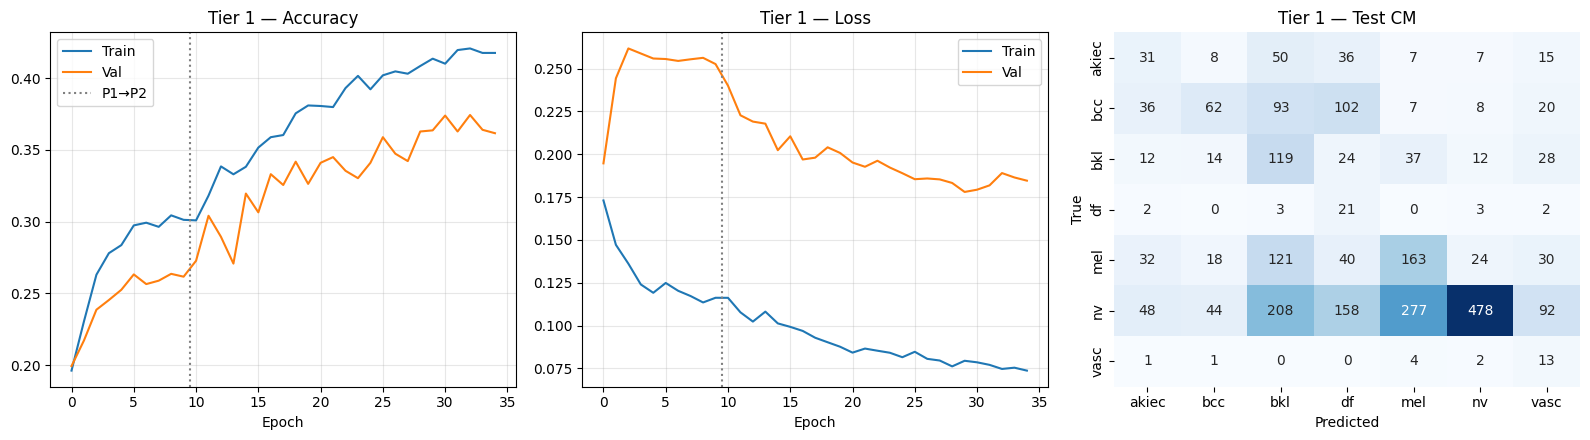


✓ Tier 1 done in 23.8 min

######################################################################
# TIER 2 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_lpft
######################################################################
  Train samples: 10,996 | Steps/epoch: 342
  Alpha: ['0.235', '0.127', '0.100', '1.000', '0.074', '0.018', '0.881']
  Total: 60,964,359 | Trainable: 60,673,799
[Phase 1] Trainable: 2,629,639

--- PHASE 1: head only, LR=1e-05 ---
Epoch 1/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.1837 - loss: 0.1639
Epoch 1: val_accuracy improved from None to 0.25169, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_lpft/best_phase1.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 70s 127ms/step - accuracy: 0.2011 - loss: 0.1626 - val_accuracy: 0.2517 - val_loss: 0.1100 - learning_rate: 1.0000e-05
Epoch 2/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.2438 - loss: 0.1372
Epoch 2: val_accuracy improved from 0.25169 to 0.32076, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_lpft/best_phase1.keras
342/342 ━━━━━━━━━━━━━━━━━━━━ 29s 86ms/step - accuracy: 0.2570 - loss: 0.1383 - val_accuracy: 0.3208 - val_loss: 0.1011 - learning_rate: 1.0000e-05
Epoch 3/10
342/342 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.2785 - loss: 0.1208
Epoch 3: val_accuracy improved from 0.32076 to 0.33148, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier2/B_

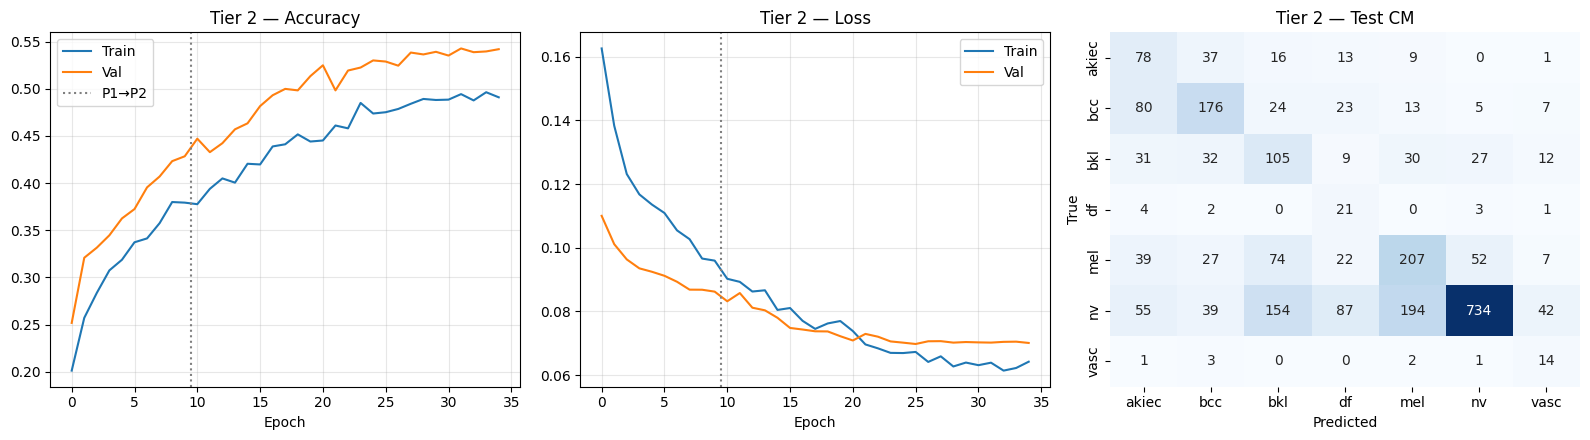


✓ Tier 2 done in 28.0 min

######################################################################
# TIER 3 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_lpft
######################################################################
  Train samples: 14,061 | Steps/epoch: 438
  Alpha: ['0.192', '0.092', '0.092', '1.000', '0.060', '0.018', '0.873']
  Total: 60,964,359 | Trainable: 60,673,799
[Phase 1] Trainable: 2,629,639

--- PHASE 1: head only, LR=1e-05 ---
Epoch 1/10
437/438 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.1909 - loss: 0.1462
Epoch 1: val_accuracy improved from None to 0.30409, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_lpft/best_phase1.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 77s 113ms/step - accuracy: 0.2105 - loss: 0.1457 - val_accuracy: 0.3041 - val_loss: 0.0901 - learning_rate: 1.0000e-05
Epoch 2/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2534 - loss: 0.1267
Epoch 2: val_accuracy improved from 0.30409 to 0.33466, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_lpft/best_phase1.keras
438/438 ━━━━━━━━━━━━━━━━━━━━ 35s 81ms/step - accuracy: 0.2689 - loss: 0.1271 - val_accuracy: 0.3347 - val_loss: 0.0842 - learning_rate: 1.0000e-05
Epoch 3/10
438/438 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.2828 - loss: 0.1077
Epoch 3: val_accuracy improved from 0.33466 to 0.37197, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier3/B_

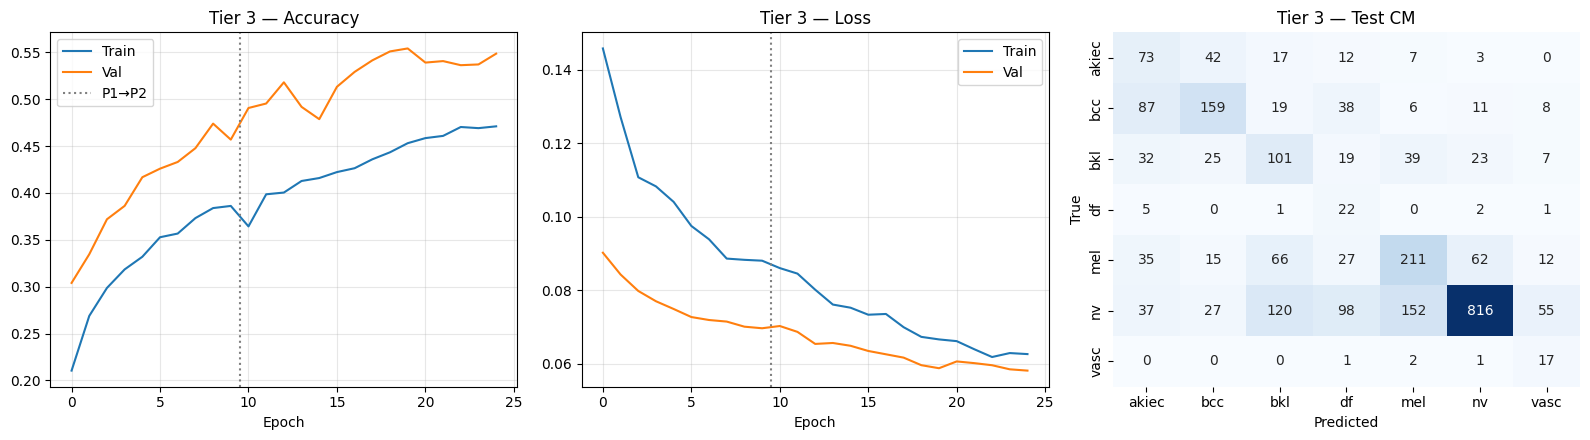


✓ Tier 3 done in 23.2 min

######################################################################
# TIER 4 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_lpft
######################################################################
  Train samples: 17,300 | Steps/epoch: 539
  Alpha: ['0.173', '0.079', '0.089', '1.000', '0.054', '0.018', '0.850']
  Total: 60,964,359 | Trainable: 60,673,799
[Phase 1] Trainable: 2,629,639

--- PHASE 1: head only, LR=1e-05 ---
Epoch 1/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.1926 - loss: 0.1424
Epoch 1: val_accuracy improved from None to 0.34736, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_lpft/best_phase1.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 83s 104ms/step - accuracy: 0.2172 - loss: 0.1381 - val_accuracy: 0.3474 - val_loss: 0.0822 - learning_rate: 1.0000e-05
Epoch 2/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.2679 - loss: 0.1186
Epoch 2: val_accuracy improved from 0.34736 to 0.37634, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_lpft/best_phase1.keras
539/539 ━━━━━━━━━━━━━━━━━━━━ 42s 78ms/step - accuracy: 0.2866 - loss: 0.1194 - val_accuracy: 0.3763 - val_loss: 0.0762 - learning_rate: 1.0000e-05
Epoch 3/10
539/539 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.2913 - loss: 0.1057
Epoch 3: val_accuracy improved from 0.37634 to 0.42358, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier4/B_

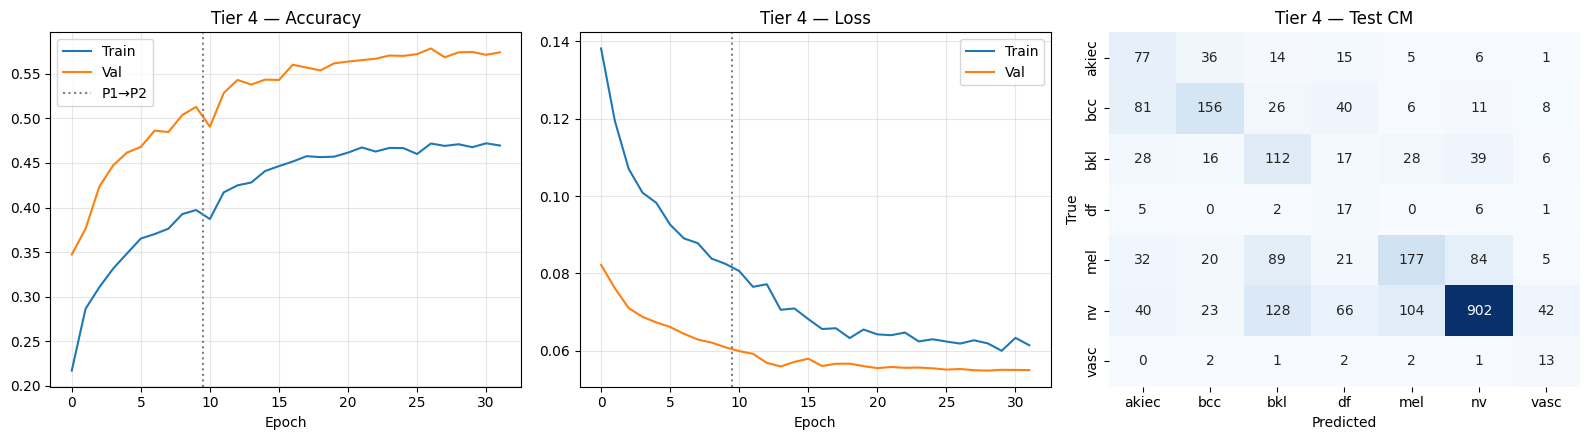


✓ Tier 4 done in 34.6 min

######################################################################
# TIER 5 — LP-FT
#  Output: /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_lpft
######################################################################
  Train samples: 20,299 | Steps/epoch: 633
  Alpha: ['0.154', '0.069', '0.086', '1.000', '0.051', '0.018', '0.880']
  Total: 60,964,359 | Trainable: 60,673,799
[Phase 1] Trainable: 2,629,639

--- PHASE 1: head only, LR=1e-05 ---
Epoch 1/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.1933 - loss: 0.1360
Epoch 1: val_accuracy improved from None to 0.36125, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_lpft/best_phase1.keras


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_lpft/best_phase1.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 90s 99ms/step - accuracy: 0.2217 - loss: 0.1331 - val_accuracy: 0.3613 - val_loss: 0.0779 - learning_rate: 1.0000e-05
Epoch 2/10
633/633 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.2674 - loss: 0.1091
Epoch 2: val_accuracy improved from 0.36125 to 0.40572, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_lpft/best_phase1.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_lpft/best_phase1.keras
633/633 ━━━━━━━━━━━━━━━━━━━━ 48s 76ms/step - accuracy: 0.2882 - loss: 0.1125 - val_accuracy: 0.4057 - val_loss: 0.0716 - learning_rate: 1.0000e-05
Epoch 3/10
632/633 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 0.3037 - loss: 0.0944
Epoch 3: val_accuracy improved from 0.40572 to 0.43549, saving model to /content/drive/MyDrive/Thesis/experiments/resnet152v2/tier5/B_l

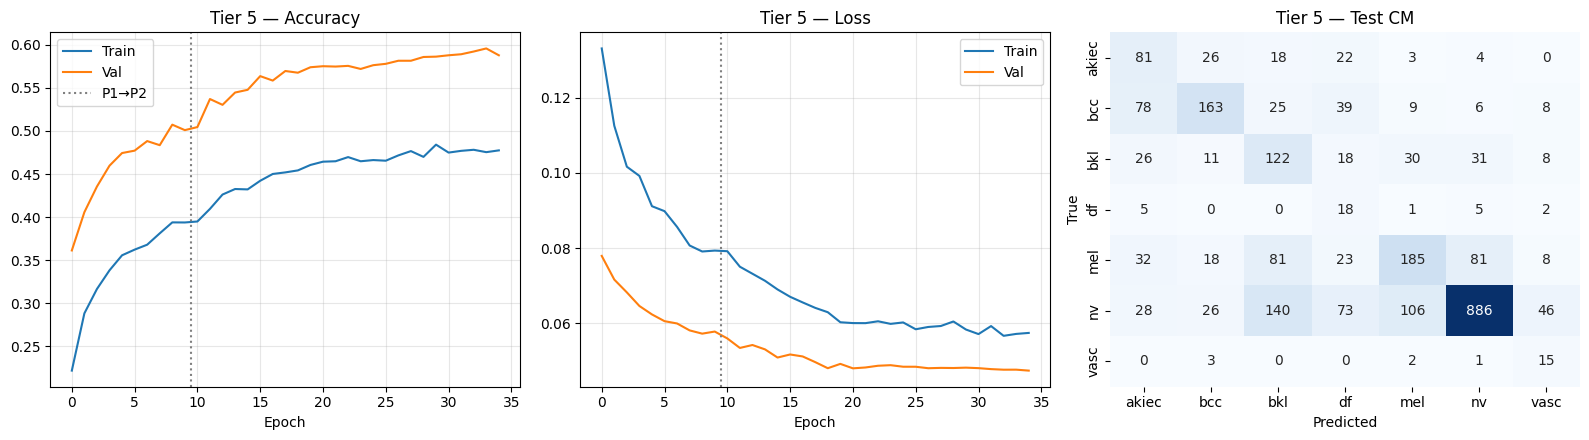


✓ Tier 5 done in 44.2 min

ALL TIERS LP-FT COMPLETE


In [15]:
# ─── Run all tiers ───
all_lpft_results = {}
for tier in TIERS_TO_RUN:
    all_lpft_results[tier] = train_tier_lpft(tier)

print('\n' + '='*70)
print('ALL TIERS LP-FT COMPLETE')
print('='*70)


## 6. Summary + comparison cu Naive (din notebook 01)


In [16]:
rows = []
for tier, res in sorted(all_lpft_results.items()):
    rows.append({
        'tier': tier,
        'epochs': res['phase1_epochs_run'] + res['phase2_epochs_run'],
        'val_acc': res['val']['accuracy'] * 100,
        'val_macro_f1': res['val']['macro_f1'],
        'test_acc': res['test']['accuracy'] * 100,
        'test_macro_f1': res['test']['macro_f1'],
        'test_weighted_f1': res['test']['weighted_f1'],
        'test_auc': res['test']['auc'],
        'time_min': res['time_minutes'],
    })

summary_df = pd.DataFrame(rows)
print(summary_df.to_string(index=False, float_format=lambda x: f'{x:.3f}'))

summary_dir = EXPERIMENTS_DIR / 'summary'
summary_dir.mkdir(parents=True, exist_ok=True)
summary_df.to_csv(summary_dir / 'lpft_summary.csv', index=False)
print(f'\nSaved: {summary_dir / "lpft_summary.csv"}')


 tier  epochs  val_acc  val_macro_f1  test_acc  test_macro_f1  test_weighted_f1  test_auc  time_min
    1      35   37.435         0.294    35.296          0.262             0.406     0.768    23.764
    2      35   54.268         0.431    53.124          0.410             0.569     0.854    28.000
    3      25   55.419         0.426    55.671          0.418             0.596     0.864    23.232
    4      32   57.840         0.455    57.859          0.420             0.611     0.868    34.563
    5      35   59.587         0.469    58.496          0.434             0.620     0.873    44.157

Saved: /content/drive/MyDrive/Thesis/experiments/resnet152v2/summary/lpft_summary.csv


In [17]:
# ─── Naive vs LP-FT comparison ───
print(f'\n{"="*70}')
print(f'NAIVE (notebook 01) vs LP-FT (notebook 02)')
print(f'{"="*70}')
print(f'{"Tier":<6} {"Naive Acc":>12} {"LP-FT Acc":>12} {"Δ Acc":>10} {"Naive F1":>12} {"LP-FT F1":>12} {"Δ F1":>10}')
print('-' * 80)

# Naive results path: experiments/efficientnetv2b0_naive/tier{N}/results.json
NAIVE_DIR = DRIVE_BASE / 'experiments' / 'resnet152v2_naive'

for tier in [1, 2, 3, 4, 5]:
    naive_path = NAIVE_DIR / f'tier{tier}' / 'results.json'
    naive_acc = naive_f1 = None
    if naive_path.exists():
        with open(naive_path) as f:
            n = json.load(f)
        naive_acc = n['test']['accuracy'] * 100
        naive_f1 = n['test']['macro_f1']

    lpft = all_lpft_results.get(tier, {})
    lpft_acc = lpft.get('test', {}).get('accuracy', 0) * 100
    lpft_f1 = lpft.get('test', {}).get('macro_f1', 0)

    if naive_acc is not None:
        d_acc = lpft_acc - naive_acc
        d_f1 = lpft_f1 - naive_f1
        print(f'{tier:<6} {naive_acc:>11.2f}% {lpft_acc:>11.2f}% {d_acc:>+9.2f}% '
              f'{naive_f1:>12.4f} {lpft_f1:>12.4f} {d_f1:>+10.4f}')
    else:
        print(f'{tier:<6} {"N/A":>12} {lpft_acc:>11.2f}% {"N/A":>10} '
              f'{"N/A":>12} {lpft_f1:>12.4f} {"N/A":>10}')



NAIVE (notebook 01) vs LP-FT (notebook 02)
Tier      Naive Acc    LP-FT Acc      Δ Acc     Naive F1     LP-FT F1       Δ F1
--------------------------------------------------------------------------------
1            57.58%       35.30%    -22.28%       0.4184       0.2619    -0.1565
2            69.52%       53.12%    -16.39%       0.5770       0.4098    -0.1673
3            70.79%       55.67%    -15.12%       0.5805       0.4179    -0.1626
4            71.03%       57.86%    -13.17%       0.5671       0.4197    -0.1474
5            73.54%       58.50%    -15.04%       0.6060       0.4344    -0.1715
